### **NAMA : DELA SHINTA SUMOMBA**  
### **NIM : H061241065 (C)**  
### **MATKUL : KECERDASAN ARTIFISIAL**

---

<div align="center">

## **Recipe Analisis Kecepatan Angin (WS10M) Tahun 2025**
</div>

Rentang tanggal: 2025-01-01 00:00:00 sampai 2025-12-31 00:00:00
Jumlah baris: 365
Data WS10M kosong: 0


,WS10M (m/s)
count,365.000000
mean,1.108493
std,0.252490
min,0.460000
25%,0.920000
50%,1.100000
75%,1.290000
max,2.000000


,Bulan,Rata_rata_WS10M,Minimum,Maksimum,Jumlah_data
0,1,0.926129,0.46,1.41,31
1,2,1.130714,0.51,2.00,28
2,3,0.965806,0.52,1.39,31
3,4,0.942667,0.56,1.51,30
4,5,1.129355,0.79,1.56,31
5,6,1.214667,0.83,1.78,30
6,7,1.167419,0.65,1.50,31
7,8,1.329355,0.95,1.66,31
8,9,1.328667,1.06,1.67,30
9,10,1.136774,0.68,1.62,31


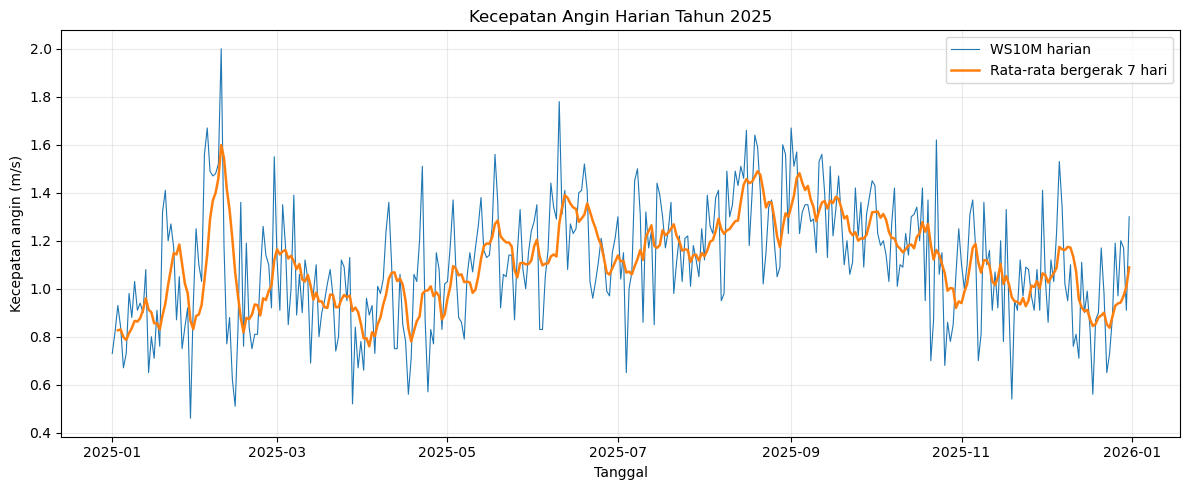

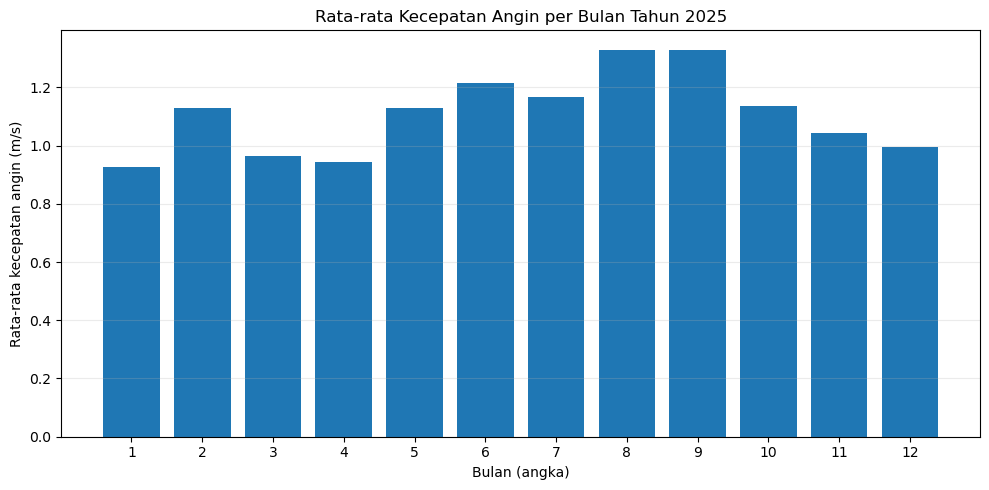

In [9]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
INPUT = ROOT / "WS10M.csv"
OUT = ROOT / "outputs"
OUT.mkdir(exist_ok=True)

df = pd.read_csv(INPUT, sep=";", skiprows=9, usecols=["YEAR", "DOY", "WS10M"])
for col in ["YEAR", "DOY", "WS10M"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")
df["YEAR"] = df["YEAR"].astype("Int64")
df["DOY"] = df["DOY"].astype("Int64")
df["Tanggal"] = pd.to_datetime(df["YEAR"].astype(str) + df["DOY"].astype(str).str.zfill(3), format="%Y%j", errors="coerce")
df["WS10M"] = df["WS10M"].replace(-999, np.nan)
df.loc[df["WS10M"] < 0, "WS10M"] = np.nan
df = df.dropna(subset=["Tanggal"]).drop_duplicates("Tanggal").sort_values("Tanggal")
df["Bulan"] = df["Tanggal"].dt.month
df["Rata_rata_bergerak_7_hari"] = df["WS10M"].rolling(7, min_periods=3).mean()
df.head()
print("Rentang tanggal:", df["Tanggal"].min(), "sampai", df["Tanggal"].max())
print("Jumlah baris:", len(df))
print("Data WS10M kosong:", int(df["WS10M"].isna().sum()))
display(df["WS10M"].describe().to_frame(name="WS10M (m/s)"))
monthly = df.groupby("Bulan").agg(Rata_rata_WS10M=("WS10M", "mean"), Minimum=("WS10M", "min"), Maksimum=("WS10M", "max"), Jumlah_data=("WS10M", "count")).reset_index()
display(monthly)
df.to_csv(OUT / "data_harian_bersih.csv", index=False, date_format="%Y-%m-%d")
monthly.to_csv(OUT / "ringkasan_bulanan.csv", index=False)
summary = df["WS10M"].describe().rename_axis("Statistik").reset_index(name="Nilai")
summary.to_csv(OUT / "statistik_deskriptif.csv", index=False)

plt.figure(figsize=(12, 5))
plt.plot(df["Tanggal"], df["WS10M"], linewidth=.8, label="WS10M harian")
plt.plot(df["Tanggal"], df["Rata_rata_bergerak_7_hari"], linewidth=1.8, label="Rata-rata bergerak 7 hari")
plt.title("Kecepatan Angin Harian Tahun 2025")
plt.xlabel("Tanggal"); plt.ylabel("Kecepatan angin (m/s)")
plt.grid(True, alpha=.25); plt.legend(); plt.tight_layout()
plt.savefig(OUT / "grafik_kecepatan_angin_harian.png", dpi=180)
plt.show()
plt.figure(figsize=(10, 5))
plt.bar(monthly["Bulan"].astype(str), monthly["Rata_rata_WS10M"])
plt.title("Rata-rata Kecepatan Angin per Bulan Tahun 2025")
plt.xlabel("Bulan (angka)"); plt.ylabel("Rata-rata kecepatan angin (m/s)")
plt.grid(axis="y", alpha=.25); plt.tight_layout()
plt.savefig(OUT / "grafik_rata_rata_bulanan.png", dpi=180)
plt.show()